In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
FIG = "../results/figures/"

values = pd.read_csv("../data/train_values.csv", index_col="building_id")
labels = pd.read_csv("../data/train_labels.csv", index_col="building_id")
df = values.join(labels)
print(df.shape)
df.head()

Matplotlib is building the font cache; this may take a moment.


(260601, 39)


,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,...,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
building_id,,,,,,,,,,,,,,,,,,,,,
802906,6,487,12198,2,30,6,5,t,r,n,...,0,0,0,0,0,0,0,0,0,3
28830,8,900,2812,2,10,8,7,o,r,n,...,0,0,0,0,0,0,0,0,0,2
94947,21,363,8973,2,10,5,5,t,r,n,...,0,0,0,0,0,0,0,0,0,3
590882,22,418,10694,2,10,6,5,t,r,n,...,0,0,0,0,0,0,0,0,0,2
201944,11,131,1488,3,30,8,9,t,r,n,...,0,0,0,0,0,0,0,0,0,3


In [2]:
print("Missing values:", df.isnull().sum().sum())
print(df.dtypes.value_counts())
df[["age", "count_floors_pre_eq", "area_percentage", "height_percentage"]].describe()

Missing values: 0
int64    31
str       8
Name: count, dtype: int64


,age,count_floors_pre_eq,area_percentage,height_percentage
count,260601.000000,260601.000000,260601.000000,260601.000000
mean,26.535029,2.129723,8.018051,5.434365
std,73.565937,0.727665,4.392231,1.918418
min,0.000000,1.000000,1.000000,2.000000
25%,10.000000,2.000000,5.000000,4.000000
50%,15.000000,2.000000,7.000000,5.000000
75%,30.000000,2.000000,9.000000,6.000000
max,995.000000,9.000000,100.000000,32.000000


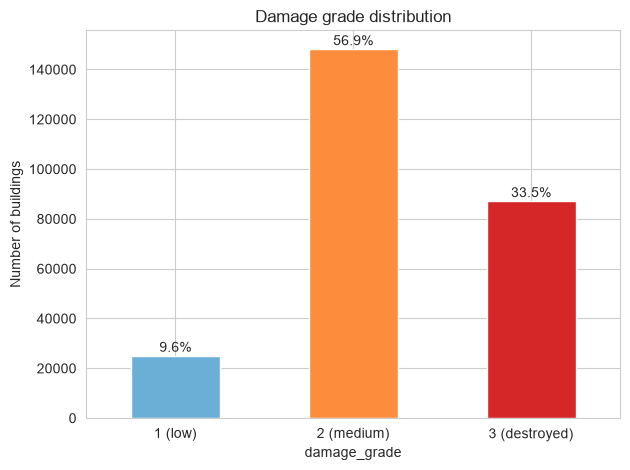

In [3]:
counts = df["damage_grade"].value_counts().sort_index()
ax = counts.plot(kind="bar", color=["#6baed6", "#fd8d3c", "#d62728"])
ax.set_xticklabels(["1 (low)", "2 (medium)", "3 (destroyed)"], rotation=0)
ax.set_ylabel("Number of buildings")
ax.set_title("Damage grade distribution")
for i, v in enumerate(counts):
    ax.text(i, v + 1500, f"{v/len(df):.1%}", ha="center")
plt.tight_layout()
plt.savefig(FIG + "01_class_distribution.png", dpi=150)
plt.show()

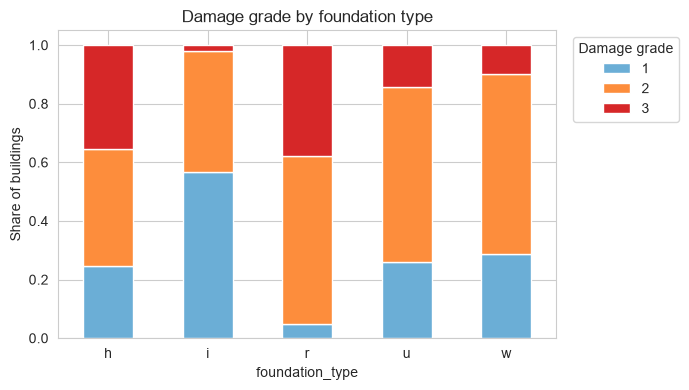

In [4]:
def stacked_share(col, fname, title, rotate=0):
    share = pd.crosstab(df[col], df["damage_grade"], normalize="index")
    ax = share.plot(kind="bar", stacked=True,
                    color=["#6baed6", "#fd8d3c", "#d62728"], figsize=(7, 4))
    ax.set_ylabel("Share of buildings")
    ax.set_title(title)
    ax.legend(title="Damage grade", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.xticks(rotation=rotate)
    plt.tight_layout()
    plt.savefig(FIG + fname, dpi=150)
    plt.show()

stacked_share("foundation_type", "02_damage_by_foundation.png",
              "Damage grade by foundation type")

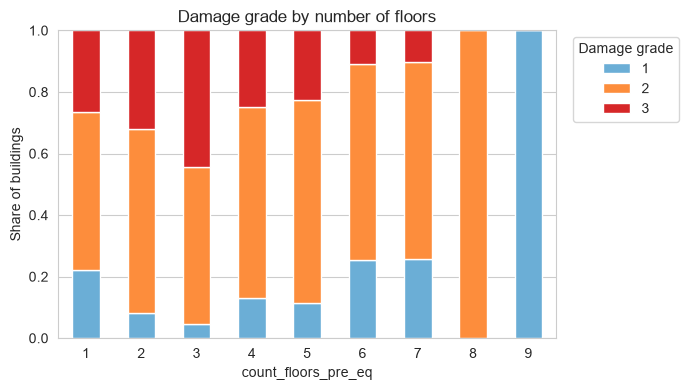

In [5]:
stacked_share("count_floors_pre_eq", "03_damage_by_floors.png",
              "Damage grade by number of floors")

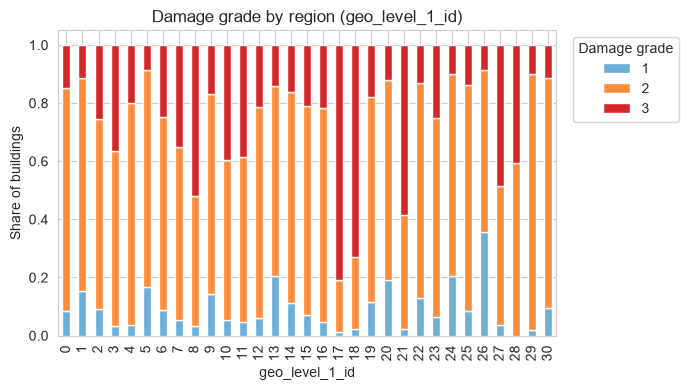

In [6]:
stacked_share("geo_level_1_id", "04_damage_by_geo1.png",
              "Damage grade by region (geo_level_1_id)", rotate=90)

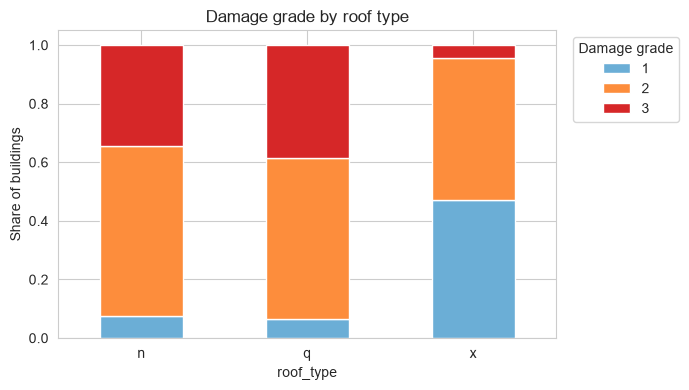

In [7]:
stacked_share("roof_type", "05_damage_by_roof.png", "Damage grade by roof type")